# Object Detection with YOLO

*   Object Detection
*   YOLO for Object Detection
    * Dataset formats
    * Fine-tuning with a custom dataset
---

# YOLO for Object Detection

*   There are several open source implementations of each version of YOLO.
*   For this exercise, we will not be implementing the YOLO from scratch as it is a challenging model and requires many customized elements.
*   We will use the official Ultralytics YOLO11 implementation for this exercise.
*  The Ultralytics YOLO implementation is available as a Python package that can be installed via pip.

In [ ]:
! pip install ultralytics==8.3.228

In [ ]:
# check
import ultralytics
ultralytics.checks()

## YOLO model - first test

In [ ]:
from ultralytics import YOLO

# Load a model
# model = YOLO('yolo11n.yaml')  # build a new model from scratch
model = YOLO('yolo11n.pt')  # load a pretrained model (recommended for training)
# Use the model
results = model('https://ultralytics.com/images/bus.jpg')  # predict on an image

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot())
plt.axis('off')
plt.show()

**Why are the people blue?** `results[0].plot()` returns the image in OpenCV's BGR channel order, but `plt.imshow` expects RGB, so red and blue are swapped (red person boxes look blue). Converting with `cv2.cvtColor(..., cv2.COLOR_BGR2RGB)`, as in the plot below, fixes it.

In [ ]:
# Understanding the Results object
# print(type(results[0]))
# print(dir(results[0]))
# print(help(results[0]))

In [ ]:
# Understanding the Boxes object
# print(type(results[0].boxes))
# print(dir(results[0].boxes))
# print(help(results[0].boxes))

In [ ]:
# Plotting the results in a more customizable way can be done using matplotlib by accessing
# the boxes and labels from the results object.
import cv2
import matplotlib

boxes = results[0].boxes
labels = results[0].names

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(cv2.cvtColor(results[0].orig_img, cv2.COLOR_BGR2RGB))

# define a color map for different classes
colors = matplotlib.colormaps.get_cmap('tab20')

# plot each box
for box in boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu()
    conf = box.conf[0].cpu()
    cls = int(box.cls[0])
    label = labels[cls]

    # create a rectangle patch
    rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor=colors(cls), facecolor='none')
    ax.add_patch(rect)
    ax.text(x1, y1 - 10, f'{label} {conf:.2f}', color='white', fontsize=12, backgroundcolor=colors(cls))

plt.axis('off')
plt.title('Detected Objects')
plt.show()


# YOLO customization and training with custom data
*   In this exercise, we will fine-tune a pre-trained YOLO model on a custom dataset.
*   We will prepare the dataset in the required format.
*   We will customize the YOLO model configuration to fit our dataset.

We will use RoboFlow's blood cell detection dataset for this exercise:
https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na

This dataset contains microscopic images of different cells:

* PC - Platelets / Thrombocytes - Small, non-nucleated blood cells essential for hemostasis (stopping bleeding). They clump together to form a plug at the site of a damaged blood vessel wall.
* RBC - Red Blood Cells / Erythrocytes - The most abundant blood cells, responsible for transporting oxygen from the lungs to the body's tissues and carrying carbon dioxide back to the lungs.
* WBC - White Blood Cells / Leukocytes - These cells are the core components of the immune system, defending the body against infections, foreign invaders (bacteria, viruses), and abnormal cells.

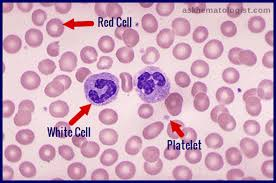

Reference:
```
@misc{
    blood-cell-st9na_dataset,
    title = { blood cell Dataset },
    type = { Open Source Dataset },
    author = { tumor },
    howpublished = { \url{ https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na } },
    url = { https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na },
    journal = { Roboflow Universe },
    publisher = { Roboflow },
    year = { 2024 },
    month = { sep },
    note = { visited on 2025-11-17 },
    }

```



### Understanding the COCO and YOLO dataset formats

In [ ]:
# COCO format annotation example
dummy_coco_annotation = {
    "images": [
        {
            "id": 1,
            "width": 640,
            "height": 480,
            "file_name": "image1.jpg"
        },
        {
            "id": 2,
            "width": 800,
            "height": 600,
            "file_name": "image2.jpg"
        }
    ],
    "annotations": [
        {
            "id": 1,
            "image_id": 1,
            "category_id": 1,
            "bbox": [100, 150, 200, 300],  # [x, y, width, height]
            "area": 60000,
            "iscrowd": 0
        },
        {
            "id": 2,
            "image_id": 2,
            "category_id": 1,
            "bbox": [50, 75, 100, 150],
            "area": 15000,
            "iscrowd": 0
        },
        {
            "id": 3,
            "image_id": 2,
            "category_id": 2,
            "bbox": [300, 400, 120, 180],
            "area": 5000,
            "iscrowd": 0
        }
    ],
    "categories": [
        {
            "id": 1,
            "name": "person"
        },
        {
            "id": 2,
            "name": "dog"
        }
    ]
}

YOLO expects the data to be in a different format:

```
├── data.yaml
├── test
│   ├── images
│   │   ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.jpg
│   └── labels
│       ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.txt
├── train
│   ├── images
│   └── labels
└── valid
    ├── images
    └── labels
```

data.yaml:
```
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['PC', 'RBC', 'WBC']
```


### Prepare data

Load the `_annotations.coco.json` from `blood_cell.v1i.coco/train` folder.

Our current data structure is following:

```
├── test
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_test_image.jpg
├── train
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_train_image.jpg
└── valid
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_val_image.jpg
```

We need to convert them to YOLO folder structure and create the missing label txt files and `data.yaml` file.

***Note that you can already download the same data in YOLO format from roboflow, but in most of the real-world scenarios, you will have to do this manually. This COCO to YOLO conversion is a simple exercise to get to understand it and be prepared in the future.***

Create a function `coco_to_yolo(input_folder, output_folder)` that does the following:
* Creates `images` and `labels` folder in `output_folder`.
* Copies all the image files (`.jpg, .png` etc) to the newly created `images` folder.
* Reads `input_folder/_annotations.coco.json` into a dictionary.
* Extracts annotations and reformats them into a YOLO format and write into a `{image_name}.txt` file inside the newly created `labels` folder. The content of `{image_name}.txt` should be as follows:
    ```
      class_id x_center y_center width height
      class_id x_center y_center width height
      ...
    ```
    where each line is one bounding box belonging to `{image_name}.jpg`.

Call the function three times:
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/train'), os.path.join(root_path, 'blood_cell.v1i.yolov11/train'))`
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/valid'), os.path.join(root_path, 'blood_cell.v1i.yolov11/valid'))`
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/test'), os.path.join(root_path, 'blood_cell.v1i.yolov11/test'))`


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Upload blood_cell.v1i.coco.zip to this Drive folder first (change it as needed)
drive_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO"
!unzip -q -o "{drive_path}/blood_cell.v1i.coco.zip" -d /content/blood_cell.v1i.coco

In [ ]:
import os
import json
import shutil

def coco_to_yolo(input_folder, output_folder):
    images_dir = os.path.join(output_folder, "images")
    labels_dir = os.path.join(output_folder, "labels")

    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(labels_dir, exist_ok=True)

    # move images
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    for f in os.listdir(input_folder):
        src = os.path.join(input_folder, f)
        if os.path.isfile(src):
            ext = os.path.splitext(f)[1].lower()
            if ext in exts:
                shutil.copy(src, os.path.join(images_dir, f))

    # load COCO
    coco_path = os.path.join(input_folder, "_annotations.coco.json")
    with open(coco_path, "r") as f:
        coco = json.load(f)

    images = {img["id"]: img for img in coco["images"]}
    anns_by_img = {}
    for ann in coco["annotations"]:
        iid = ann["image_id"]
        anns_by_img.setdefault(iid, []).append(ann)

    # generate YOLO txt
    for img_id, img_info in images.items():
        file_name = img_info["file_name"]
        width = img_info["width"]
        height = img_info["height"]

        stem = os.path.splitext(os.path.basename(file_name))[0]
        yolo_path = os.path.join(labels_dir, stem + ".txt")

        lines = []
        for ann in anns_by_img.get(img_id, []):
            cid = ann["category_id"] - 1  # coco starts with 1, yolo needs [0, N-1]
            x, y, w, h = ann["bbox"]
            xc = (x + w / 2) / width
            yc = (y + h / 2) / height
            wn = w / width
            hn = h / height
            lines.append(f"{cid} {xc} {yc} {wn} {hn}")

        with open(yolo_path, "w") as f:
            f.write("\n".join(lines))

# change root path as needed
root_path = "/content"
coco_root_path = f"{root_path}/blood_cell.v1i.coco"
yolo_root_path = f"{root_path}/blood_cell.v1i.yolov11"
coco_to_yolo(os.path.join(coco_root_path, 'train'), os.path.join(yolo_root_path, 'train'))
coco_to_yolo(os.path.join(coco_root_path, 'valid'), os.path.join(yolo_root_path, 'valid'))
coco_to_yolo(os.path.join(coco_root_path, 'test'), os.path.join(yolo_root_path, 'test'))

Create the `data.yaml` with the new data structure

In [ ]:
# data.yaml
import os
import shutil

root_path = "/content/blood_cell.v1i.yolov11"

# create data.yaml
data_yaml = f"""
train: {os.path.join(root_path, 'train/images')}
val: {os.path.join(root_path, 'valid/images')}
test: {os.path.join(root_path, 'test/images')}

nc: 3
names: ['PC', 'RBC', 'WBC']
"""

with open(os.path.join(root_path, 'data.yaml'), 'w') as f:
    f.write(data_yaml)

We still have the coco json files, let's load it and do some simple exploration

Steps:
* Load `_annotations.coco.json` from `train` and print/plot
    * number of images
    * number of annotations
    * class distribution (number of images per class)
* Load N=5 images and plot them with bounding boxes

In [ ]:
from skimage import io
import matplotlib.pyplot as plt

coco = json.load(open(os.path.join(coco_root_path, 'train/_annotations.coco.json')))
print(f'Number of images: {len(coco["images"])}')
print(f'Number of annotations: {len(coco["annotations"])}')
# count the number of images per class
class_counts = {}
for annotation in coco["annotations"]:
    category_id = annotation["category_id"]
    category_name = coco["categories"][category_id]["name"]
    if category_name not in class_counts:
        class_counts[category_name] = 0
    class_counts[category_name] += 1

plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel('Class')
plt.ylabel('Number of images')
plt.title('Number of images per class')
plt.show()

# load 5 images and plot them with bounding boxes
for i in range(5):
    image_id = coco["images"][i]["id"]
    image_path = os.path.join(root_path, 'train/images', coco["images"][i]["file_name"])
    image = io.imread(image_path)
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    for annotation in coco["annotations"]:
        if annotation["image_id"] == image_id:
            x, y, w, h = annotation["bbox"]
            rect = plt.Rectangle((x, y), w, h, fill=False, edgecolor='red', linewidth=2)
            ax.add_patch(rect)
            if annotation["category_id"] == 1:
                color = 'red'
            elif annotation["category_id"] == 2:
                color = 'green'
            else:
                color = 'blue'
            ax.text(x, y, coco["categories"][annotation["category_id"]]["name"], color=color, fontsize=12)
    plt.show()

Do the same with the new YOLO version

Steps:
* Load all image-annotation pairs from `train` and print/plot
    * number of images
    * number of annotations
    * class distribution (number of images per class)
* Load N=5 images and plot them with bounding boxes

In [ ]:
root_path = "/content/blood_cell.v1i.yolov11"

# load all image-annotation pairs from train
image_paths = []
label_paths = []
for image_path in os.listdir(os.path.join(root_path, 'train/images')):
    image_paths.append(os.path.join(root_path, 'train/images', image_path))
    label_paths.append(os.path.join(root_path, 'train/labels', os.path.splitext(image_path)[0] + '.txt'))

print(f'Number of images: {len(image_paths)}')
print(f'Number of annotation files: {len(label_paths)}')
number_of_annotations = 0
class_counts = {}
for label_path in label_paths:
    with open(label_path, 'r') as f:
        for line in f.readlines():
            class_id = int(line.split()[0])
            if class_id not in class_counts:
                class_counts[class_id] = 0
            class_counts[class_id] += 1
            number_of_annotations += 1

print(f'Number of annotations: {number_of_annotations}')

class_names = {0: 'PC', 1: 'RBC', 2: 'WBC'}
# map class_counts.keys() to class_names
class_counts = {class_names[k]: v for k, v in class_counts.items()}
plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel('Class')
plt.ylabel('Number of images')
plt.title('Number of images per class')
plt.show()

# plot 5 images with bounding boxes
for i in range(5):
    image_path = image_paths[i]
    label_path = label_paths[i]
    image = io.imread(image_path)
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    with open(label_path, 'r') as f:
        for line in f.readlines():
            class_id, x, y, w, h = [float(x) for x in line.split()]
            x, y, w, h = x*image.shape[1], y*image.shape[0], w*image.shape[1], h*image.shape[0]
            rect = plt.Rectangle((x-w/2, y-h/2), w, h, fill=False, edgecolor='red', linewidth=2)
            ax.add_patch(rect)
            if class_id == 0:
                color = 'red'
            elif class_id == 1:
                color = 'green'
            else:
                color = 'blue'
            ax.text(x, y, class_names[int(class_id)], color=color, fontsize=12)
    plt.show()


# Customize YOLO ("yolo11n") model

In [ ]:
from ultralytics import YOLO
import torch

model = YOLO("yolo11n.yaml")  # training from scratch

### Model training (from scratch)

In [ ]:
# change root path as needed
root_path = "/content/blood_cell.v1i.yolov11"

# https://docs.ultralytics.com/modes/train/#train-settings
model.train(
    data=f"{root_path}/data.yaml",
    name="from_scratch_50e_v1",
    epochs=50,
    batch=16,
    classes=[0, 1, 2],
    plots=True,
    exist_ok=True
)

In [ ]:
# show the training logs
runs_dir = "/content/runs"
# copy runs_dir logs to root_dir not to lose them after restart
!cp -r "/content/runs" "{drive_path}"

# Model Evaluation

In [ ]:
!pip install ultralytics==8.3.228

In [ ]:
from ultralytics import YOLO
import torch

# run_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO"
run_path = "runs/detect/from_scratch_50e_v1"
model = YOLO(f"{run_path}/weights/best.pt")

#### Qualitative evaluation


In [ ]:
import os
from skimage import io
import matplotlib.pyplot as plt
import time

# root_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11"
root_path = "blood_cell.v1i.yolov11"

test_images = os.listdir(f"{root_path}/test/images")
test_labels = os.listdir(f"{root_path}/test/labels")

categories = {
    0: "PC",
    1: "RBC",
    2: "WBC"
}

for i in range(5):
    image_path = os.path.join(f"{root_path}/test/images", test_images[i])
    label_path = os.path.splitext(image_path.replace("images", "labels"))[0] + ".txt"
    print(image_path)
    print(label_path)

    # load image and labels
    image = io.imread(image_path)
    with open(label_path, "r") as f:
        labels = f.readlines()

    start_time = time.time()
    with torch.no_grad():
        predict = model.predict(image_path)
    end_time = time.time()
    print(f"Prediction time: {end_time - start_time} seconds")
    # plot predictions and ground truth boxes
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    for label in labels:
        label = label.split()
        x, y, w, h = [float(l) for l in label[1:]]
        # these are in yolo format so it needs processing before plotting
        x, y, w, h = x*image.shape[1], y*image.shape[0], w*image.shape[1], h*image.shape[0]
        rect = plt.Rectangle((x-w/2, y-h/2), w, h, fill=False, edgecolor='green', linewidth=2)
        ax.add_patch(rect)
        if int(label[0]) == 0:
            color = 'red'
        elif int(label[0]) == 1:
            color = 'green'
        else:
            color = 'blue'
        ax.text(x-w/2, y-h/2, categories[int(label[0])], color=color, fontsize=10)

    for box in predict[0].boxes:
        x, y, w, h = box.xywh[0].tolist()
        rect = plt.Rectangle((x-w/2, y-h/2), w, h, fill=False, edgecolor='blue', linewidth=1)
        ax.add_patch(rect)
        if box.cls[0].item() == 0:
            color = 'red'
        elif box.cls[0].item() == 1:
            color = 'green'
        else:
            color = 'blue'
        ax.text(x-w/2, y-h/2, categories[int(box.cls[0].item())], color=color, fontsize=10)
    plt.show()


### Quantitiatve evaluation

* Plot Precision-Recall Curve
* Plot False-Positives-Per-Image Curve
* Print a table with mAP@0.5, mAP@0.5-0.9

We can use the built-in evaluation methods from the YOLO library, which is shown below. But we should also learn to implement these metrics from scratch, so we will do that as well.

In [ ]:
results = model.val(data="blood_cell.v1i.yolov11/data.yaml", split="test")

In [ ]:
import os
from skimage import io
import matplotlib.pyplot as plt
import time
%matplotlib inline

fig, axes = plt.subplots(3, 2, figsize=(10, 7))
ax = axes.ravel()
res_path = str(results.save_dir)
for i, res_plot in enumerate(['BoxF1_curve.png', 'BoxP_curve.png', 'BoxPR_curve.png', 'confusion_matrix_normalized.png', 'confusion_matrix.png', 'val_batch0_pred.jpg']):
    res = io.imread(f"{res_path}/{res_plot}")
    ax[i].imshow(res)
    ax[i].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# do the same manually for some curves and create FPPI as an addition
import numpy as np
import pandas as pd

def run_inference_and_collect(model_path, image_folder, label_folder):
    # predict every image once; keep predicted and ground-truth boxes as absolute [x1, y1, x2, y2]
    model = YOLO(model_path)
    images = []
    for r in model.predict(image_folder, stream=True, imgsz=640, conf=0.001, verbose=False):
        stem = os.path.splitext(os.path.basename(r.path))[0]
        c, xc, yc, w, h = np.loadtxt(os.path.join(label_folder, stem + ".txt"), ndmin=2).T
        img_height, img_width = r.orig_shape
        gt_boxes = np.stack([(xc - w / 2) * img_width, (yc - h / 2) * img_height,
                             (xc + w / 2) * img_width, (yc + h / 2) * img_height], axis=1)
        images.append({"boxes": r.boxes.xyxy.cpu().numpy(), "conf": r.boxes.conf.cpu().numpy(),
                       "cls": r.boxes.cls.cpu().numpy(), "gt_boxes": gt_boxes, "gt_cls": c})
    return images


def iou(box, boxes):
    ix1 = np.maximum(box[0], boxes[:, 0])
    iy1 = np.maximum(box[1], boxes[:, 1])
    ix2 = np.minimum(box[2], boxes[:, 2])
    iy2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / ((box[2] - box[0]) * (box[3] - box[1]) + areas - inter)


def match_detections(images, iou_thr=0.5):
    # a detection is a TP if it overlaps a not yet matched ground-truth box of the same class
    rows = []
    for im in images:
        used = np.zeros(len(im["gt_boxes"]), dtype=bool)
        for box, conf, cls in zip(im["boxes"], im["conf"], im["cls"]):  # highest confidence first
            ious = iou(box, im["gt_boxes"])
            ious[(im["gt_cls"] != cls) | used] = 0
            j = ious.argmax()
            tp = ious[j] >= iou_thr
            used[j] |= tp
            rows.append([conf, cls, tp])
    return pd.DataFrame(rows, columns=["conf", "cls", "tp"]).sort_values("conf", ascending=False)


def precision_recall(df, num_gt):
    tp_cum = df["tp"].cumsum().values
    fp_cum = (~df["tp"]).cumsum().values
    return tp_cum / (tp_cum + fp_cum), tp_cum / num_gt


def average_precision(precision, recall):
    # 11-point interpolated AP
    return np.mean([precision[recall >= r].max() if np.any(recall >= r) else 0 for r in np.linspace(0, 1, 11)])


In [ ]:
model_path = f"{run_path}/weights/best.pt"
image_folder = f"{root_path}/test/images"
label_folder = f"{root_path}/test/labels"
images = run_inference_and_collect(model_path, image_folder, label_folder)
gt_cls = np.concatenate([im["gt_cls"] for im in images])
results = match_detections(images, iou_thr=0.5)
results.head()

In [ ]:
# PR and FPPI curves (all classes together, IoU 0.5)
precision, recall = precision_recall(results, len(gt_cls))
fppi = (~results["tp"]).cumsum().values / len(images)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(recall, precision)
ax[0].set(xlabel="Recall", ylabel="Precision", title="PR Curve")
ax[1].plot(fppi, recall)
ax[1].set(xscale="log", xlabel="FPPI", ylabel="TPR", title="FPPI–TPR")
plt.show()

# mAP = AP of each class averaged over the classes, for IoU 0.5, 0.55, ..., 0.95
mAP = {}
for iou_thr in np.arange(0.5, 0.96, 0.05):
    df = match_detections(images, iou_thr)
    aps = [average_precision(*precision_recall(df[df["cls"] == c], np.sum(gt_cls == c))) for c in categories]
    mAP[round(iou_thr, 2)] = np.mean(aps)
mAP = pd.Series(mAP, name="mAP")
print(mAP)
print(f"mAP@0.5: {mAP[0.5]:.3f}   mAP@0.5:0.95: {mAP.mean():.3f}")